# Atividade Prática — Redução de Dimensionalidade e Pipeline de Agrupamento


## Contexto
A HELP International é uma ONG humanitária que arrecadou US$ 10 milhões para ações de combate à pobreza e de apoio em situações de desastre. A direção precisa decidir como distribuir esses recursos entre os países e solicitou à equipe de dados uma classificação dos países em **três níveis**, com base em indicadores socioeconômicos e de saúde.

## Objetivo
Aplicar a Análise de Componentes Principais (PCA) a uma base real e construir um *pipeline* de padronização, redução de dimensionalidade e agrupamento (K-Means), avaliando o efeito de cada etapa sobre o resultado.

## Dados
Base *Unsupervised Learning on Country Data*, disponível no Kaggle: 167 países e 9 indicadores. Os dados já estão carregados neste notebook.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_paises.pkl`, gerado na Parte 7, que será utilizado na aula de implantação.

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, com base nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados.
- Não altere o DataFrame original `df`.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

In [11]:
# @title Configuração do ambiente (célula fornecida)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline
import joblib

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [12]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")

print("Path to dataset files:", path)

df = pd.read_csv(path+"/Country-data.csv")
print(f"Base carregada: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Path to dataset files: /Users/joaopedrolimabarbosa/.cache/kagglehub/datasets/rohan0301/unsupervised-learning-on-country-data/versions/2
Base carregada: 167 linhas e 10 colunas.


### Dicionário de dados

| Coluna | Significado |
|---|---|
| `country` | nome do país |
| `child_mort` | mortes de crianças menores de 5 anos a cada 1.000 nascidos vivos |
| `exports` | exportações de bens e serviços per capita, em % do PIB per capita |
| `health` | gasto total com saúde per capita, em % do PIB per capita |
| `imports` | importações de bens e serviços per capita, em % do PIB per capita |
| `income` | renda líquida por pessoa (US$) |

| Coluna | Significado |
|---|---|
| `inflation` | taxa anual de crescimento do PIB total, em % (indicador de inflação) |
| `life_expec` | expectativa de vida ao nascer, em anos |
| `total_fer` | número médio de filhos por mulher |
| `gdpp` | PIB per capita (US$) |

## Parte 1 — Preparação e análise das escalas

**Tarefa 1.1.** Crie a variável `X`, contendo apenas os indicadores numéricos, e a variável `paises`, contendo os nomes dos países na mesma ordem das linhas de `X`. Verifique se há valores ausentes.

**Tarefa 1.2.** Apresente, para cada indicador, a média, o desvio padrão, o mínimo e o máximo.

In [13]:
# Tarefas 1.1 e 1.2
X = df.drop(columns=["country"])
paises = df["country"]
print("Valores ausentes:", X.isna().sum().sum())
X.agg(["mean", "std", "min", "max"]).T.round(2)

Valores ausentes: 0


,mean,std,min,max
child_mort,38.27,40.33,2.60,208.00
exports,41.11,27.41,0.11,200.00
health,6.82,2.75,1.81,17.90
imports,46.89,24.21,0.07,174.00
income,17144.69,19278.07,609.00,125000.00
inflation,7.78,10.57,-4.21,104.00
life_expec,70.56,8.89,32.10,82.80
total_fer,2.95,1.51,1.15,7.49
gdpp,12964.16,18328.70,231.00,105000.00


**Questão 1.** Quais indicadores apresentam as maiores escalas numéricas? Que efeito você espera que essa diferença de escala produza sobre o PCA?

**Resposta:**

Os indicadores com as maiores escalas são `income` (média de 17.145 e máximo de 125.000) e `gdpp` (média de 12.964 e máximo de 105.000), os dois em dólares. Os outros ficam em escalas bem menores, entre percentuais, anos e taxas, quase todos abaixo de 200 (o `total_fer`, por exemplo, vai de 1,15 a 7,49).

Como o PCA procura as direções de maior variância, espero que `income` e `gdpp` dominem o resultado só por causa da unidade de medida, e que os outros indicadores quase não influenciem os componentes.

## Parte 2 — Efeito da padronização

**Tarefa 2.1.** Aplique o PCA a `X` **sem** padronização. Informe a proporção da variância explicada pela PC1 e os pesos (*loadings*) de cada indicador nesse componente.

**Tarefa 2.2.** Padronize `X`, armazenando o resultado em `X_pad`, e repita a análise da Tarefa 2.1.

In [14]:
# Tarefas 2.1 e 2.2
pca_bruto = PCA().fit(X)
print("PC1 sem padronizar:", round(pca_bruto.explained_variance_ratio_[0], 3))
print(pd.Series(pca_bruto.components_[0], index=X.columns).round(3))

scaler = StandardScaler()
X_pad = scaler.fit_transform(X)
pca_pad = PCA().fit(X_pad)
print("\nPC1 padronizado:", round(pca_pad.explained_variance_ratio_[0], 3))
print(pd.Series(pca_pad.components_[0], index=X.columns).round(3))

PC1 sem padronizar: 0.948
child_mort   -0.001
exports       0.001
health        0.000
imports       0.000
income        0.727
inflation    -0.000
life_expec    0.000
total_fer    -0.000
gdpp          0.687
dtype: float64

PC1 padronizado: 0.46
child_mort   -0.420
exports       0.284
health        0.151
imports       0.161
income        0.398
inflation    -0.193
life_expec    0.426
total_fer    -0.404
gdpp          0.393
dtype: float64


**Questão 2.** Compare os dois resultados. Por que a PCA sem padronização não é adequada para esta base?

**Resposta:**

Sem padronização, a PC1 explica 94,8% da variância e quase todo o peso fica em `income` (0,727) e `gdpp` (0,687). Os outros indicadores têm peso praticamente zero (`child_mort` -0,001 e `life_expec` 0,000, por exemplo), então a PC1 é só renda e PIB. Com a padronização, a PC1 explica 46,0% e o peso se distribui entre todos os indicadores: `life_expec` (0,426), `child_mort` (-0,420), `total_fer` (-0,404), `income` (0,398), `gdpp` (0,393), `exports` (0,284), entre outros.

Os 94,8% da primeira versão não são informação de verdade, são efeito da escala em dólares. Por isso o PCA sem padronização não é adequado: ele ignora mortalidade infantil, expectativa de vida e fertilidade, que são justamente os indicadores de saúde que a ONG precisa considerar.

## Parte 3 — Número de componentes

**Tarefa 3.1.** A partir de `X_pad`, construa um gráfico com a variância explicada por componente e a variância acumulada.

**Tarefa 3.2.** Determine quantos componentes são necessários para preservar 80% e 90% da variância e confirme os valores utilizando `PCA(n_components=0.8)` e `PCA(n_components=0.9)`.

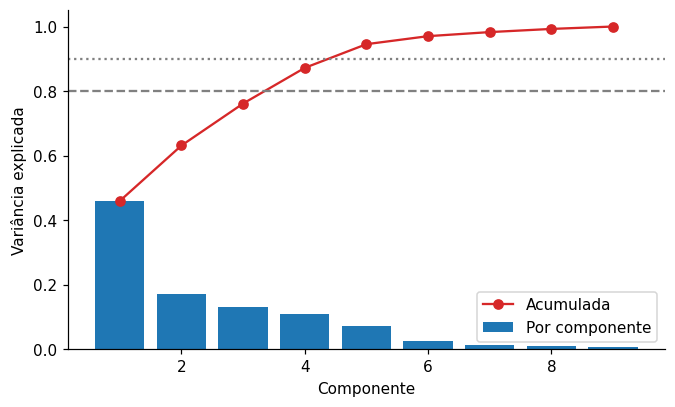

Componentes p/ 80%: 4 · p/ 90%: 5
Confirmando com PCA: 4 5


In [15]:
# Tarefas 3.1 e 3.2
var = pca_pad.explained_variance_ratio_
acum = np.cumsum(var)
comp = range(1, len(var) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(comp, var, label="Por componente")
ax.plot(comp, acum, "o-", color="tab:red", label="Acumulada")
ax.axhline(0.8, ls="--", color="gray")
ax.axhline(0.9, ls=":", color="gray")
ax.set_xlabel("Componente")
ax.set_ylabel("Variância explicada")
ax.legend()
plt.show()

print("Componentes p/ 80%:", np.argmax(acum >= 0.8) + 1, "· p/ 90%:", np.argmax(acum >= 0.9) + 1)
print("Confirmando com PCA:", PCA(n_components=0.8).fit(X_pad).n_components_,
      PCA(n_components=0.9).fit(X_pad).n_components_)

**Questão 3.** Quantos componentes você utilizaria para (a) visualizar os países em um gráfico e (b) alimentar o algoritmo de agrupamento? Justifique cada escolha.

**Resposta:**

**(a) Visualização:** eu usaria 2 componentes, porque o gráfico só tem dois eixos. Pelo gráfico da variância acumulada, eles preservam cerca de 63% da variância, o que é aceitável para olhar a distribuição dos países e identificar os que fogem do padrão.

**(b) Agrupamento:** eu usaria 5 componentes, que é o número necessário para passar de 90% da variância (com 4 componentes dá 80%). O K-Means calcula distâncias no espaço inteiro, então descartar muita informação pode mudar os grupos. Com 5 componentes a base cai de 9 para 5 colunas e ainda mantém quase tudo que importa, descartando só o que parece ruído nas últimas componentes.

## Parte 4 — Interpretação dos componentes

**Tarefa 4.1.** Apresente uma tabela com os pesos dos indicadores nos três primeiros componentes, armazenada na variável `pesos`.

**Tarefa 4.2.** Construa um gráfico de dispersão de todos os países no plano PC1 × PC2, destacando e rotulando, no mínimo: Brazil, Norway, United States, India, Niger, Haiti, Singapore e Luxembourg.

,PC1,PC2,PC3
child_mort,-0.420,0.193,-0.030
exports,0.284,0.613,0.145
health,0.151,-0.243,-0.597
imports,0.161,0.672,-0.300
income,0.398,0.023,0.302
inflation,-0.193,-0.008,0.643
life_expec,0.426,-0.223,0.114
total_fer,-0.404,0.155,0.020
gdpp,0.393,-0.046,0.123


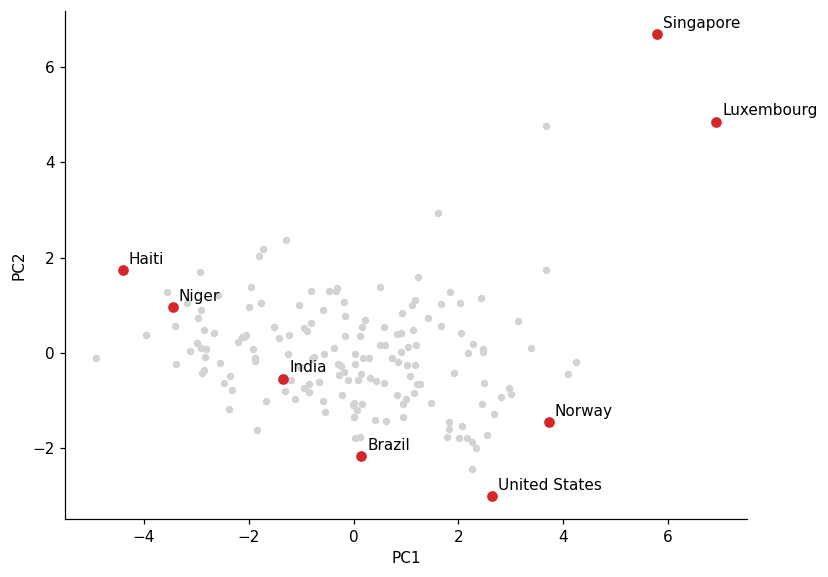

In [16]:
# Tarefas 4.1 e 4.2
pca = PCA(n_components=3).fit(X_pad)
pesos = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2", "PC3"]).round(3)
display(pesos)

Z = pca.transform(X_pad)
destaque = ["Brazil", "Norway", "United States", "India", "Niger", "Haiti", "Singapore", "Luxembourg"]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Z[:, 0], Z[:, 1], s=15, color="lightgray")
for nome in destaque:
    i = np.where(paises == nome)[0][0]
    ax.scatter(Z[i, 0], Z[i, 1], color="tab:red")
    ax.annotate(nome, (Z[i, 0], Z[i, 1]), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
plt.show()

**Questão 4.** Com base nos pesos, atribua um nome interpretativo à PC1 e à PC2, justificando com os indicadores de maior peso positivo e negativo.

**Resposta:**

**PC1: nível de desenvolvimento (bem-estar socioeconômico).** Os maiores pesos positivos são `life_expec` (0,426), `income` (0,398), `gdpp` (0,393) e `exports` (0,284). Os maiores pesos negativos são `child_mort` (-0,420), `total_fer` (-0,404) e `inflation` (-0,193). Países com valores altos de PC1 têm renda e expectativa de vida altas e mortalidade infantil e fertilidade baixas (como Norway e United States, à direita no gráfico). Países com PC1 baixo são o oposto (Haiti e Niger, à esquerda).

**PC2: abertura comercial (peso do comércio exterior na economia).** Os maiores pesos positivos são `imports` (0,672) e `exports` (0,613). Os pesos negativos são menores, em `health` (-0,243) e `life_expec` (-0,223), e `income` e `gdpp` ficam perto de zero. Ou seja, a PC2 separa os países pelo tamanho do comércio exterior em relação ao PIB, quase independente da renda.

**Questão 5.** Interprete a posição do Brasil no gráfico. Em seguida, explique por que Singapore e Luxembourg aparecem afastados dos demais países.

**Resposta:**

**Brasil:** fica perto de 0 na PC1 e abaixo de -2 na PC2. Na PC1, isso significa desenvolvimento intermediário, nem entre os mais pobres nem entre os mais ricos. Na PC2, significa comércio exterior pequeno em relação ao PIB (exportações e importações baixas) e gasto em saúde um pouco mais alto. Eu interpreto como uma economia grande e relativamente fechada, de desenvolvimento intermediário.

**Singapore e Luxembourg:** aparecem isolados no canto superior direito (PC2 de aproximadamente 6,7 e 4,8; PC1 de aproximadamente 5,8 e 6,9). Os dois têm exportações e importações muito acima do resto da base: Singapore tem 200 e 174 e Luxembourg 175 e 142 (em % do PIB), contra médias de 41 e 47. Além disso, têm renda alta e expectativa de vida alta (Singapore 82,7 anos, Luxembourg com `gdpp` de 105.000). São pequenas economias que funcionam como centros de comércio e finanças, então se destacam nos dois eixos ao mesmo tempo e são valores atípicos.

## Parte 5 — Pipeline de agrupamento

**Tarefa 5.1.** Construa um *pipeline* denominado `modelo`, composto por `StandardScaler`, `PCA(n_components=0.9)` e `KMeans(n_clusters=3, n_init=10, random_state=42)`. Ajuste-o sobre `X` (dados originais, sem padronização prévia) e armazene os grupos na variável `grupos`. Informe quantos componentes o PCA utilizou dentro do pipeline.

**Tarefa 5.2.** Compare `grupos` com o resultado de três variações, utilizando o índice de Rand ajustado (`adjusted_rand_score`) e o tamanho de cada grupo:
- (a) K-Means sobre `X_pad`, sem PCA;
- (b) o mesmo pipeline com `PCA(n_components=2)`;
- (c) K-Means sobre `X`, sem padronização e sem PCA.

In [17]:
# Tarefas 5.1 e 5.2
modelo = make_pipeline(StandardScaler(), PCA(n_components=0.9),
                       KMeans(n_clusters=3, n_init=10, random_state=42))
grupos = modelo.fit_predict(X)
print("Componentes do PCA no pipeline:", modelo.named_steps["pca"].n_components_)
print("Tamanhos:", np.bincount(grupos))

g_a = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_pad)
modelo_b = make_pipeline(StandardScaler(), PCA(n_components=2),
                         KMeans(n_clusters=3, n_init=10, random_state=42))
g_b = modelo_b.fit_predict(X)
g_c = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)

for nome, g in [("(a) sem PCA", g_a), ("(b) PCA com 2 comp.", g_b), ("(c) sem padronizar e sem PCA", g_c)]:
    print(nome, "· ARI:", round(adjusted_rand_score(grupos, g), 3), "· tamanhos:", np.bincount(g))

Componentes do PCA no pipeline: 5
Tamanhos: [36 84 47]
(a) sem PCA · ARI: 1.0 · tamanhos: [36 47 84]
(b) PCA com 2 comp. · ARI: 0.318 · tamanhos: [ 3 72 92]
(c) sem padronizar e sem PCA · ARI: 0.39 · tamanhos: [  7 128  32]


**Questão 6.** Interprete os três resultados. Em particular, explique por que 2 componentes são adequados para visualizar os países, mas alteram significativamente o agrupamento.

**Resposta:**

**(a) K-Means sobre `X_pad`, sem PCA:** o ARI foi 1,0 e os tamanhos são iguais aos do pipeline (36, 47 e 84). Os agrupamentos são idênticos, então os 5 componentes do PCA com 90% da variância só descartaram ruído e não mudaram nada. O PCA com 5 componentes comprimiu os dados sem perder o que separa os grupos.

**(b) Pipeline com 2 componentes:** o ARI caiu para 0,318 e os tamanhos ficaram em 3, 72 e 92, com um grupo de apenas 3 países (provavelmente os países extremos do eixo de comércio, como os do gráfico). Com 2 componentes sobra só cerca de 63% da variância, e o restante da informação que separava os países deixou de existir.

**(c) K-Means sobre `X`, sem padronização e sem PCA:** o ARI foi 0,39 e os tamanhos ficaram em 7, 128 e 32. Sem padronizar, a distância euclidiana é dominada por `income` e `gdpp` (em dólares) e os indicadores de saúde quase não contam, então o agrupamento é basicamente por renda.

**Por que 2 componentes servem para visualizar mas mudam o agrupamento:** para visualizar basta uma imagem aproximada dos dados, e perder cerca de 37% da variância é tolerável. Para agrupar, o K-Means usa as distâncias entre todos os países no espaço inteiro, e remover componentes altera essas distâncias, então os grupos mudam.

**Tarefa 5.3.** Calcule o coeficiente de silhueta para k de 2 a 6, aplicando o K-Means sobre os dados já padronizados e reduzidos pelo PCA do pipeline (dica de API: `modelo[:-1].transform(X)` aplica todas as etapas exceto a última).

In [18]:
# Tarefa 5.3
Z90 = modelo[:-1].transform(X)
for k in range(2, 7):
    rotulos = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z90)
    print("k =", k, "· silhueta:", round(silhouette_score(Z90, rotulos), 3))

k = 2 · silhueta: 0.304
k = 3 · silhueta: 0.308
k = 4 · silhueta: 0.329
k = 5 · silhueta: 0.33
k = 6 · silhueta: 0.256


**Questão 7.** A métrica de silhueta confirma a escolha de três grupos feita pela ONG? Como conciliar o critério técnico com a necessidade da organização?

**Resposta:**

Não confirma totalmente. Os valores de silhueta foram: k=2: 0,304; k=3: 0,308; k=4: 0,329; k=5: 0,330; k=6: 0,256. O melhor valor é com k=5 (0,330), seguido por k=4, e o k=3 não é o maior. Mas as diferenças são pequenas (de 0,308 para 0,330, só 0,02) e todos os valores ficam perto de 0,3, o que indica grupos pouco separados: os países formam mais um contínuo do que blocos bem definidos.

Para conciliar, eu manteria k=3, porque a ONG precisa de três níveis de prioridade para decidir como distribuir os recursos, e a silhueta do k=3 é praticamente igual à de k=2 e próxima à dos melhores. Na atividade complementar A, o k=4 só criou um grupo de 3 países (Luxembourg, Malta e Singapore), que não ajuda na decisão da ONG. O critério técnico é um apoio à decisão, não precisa ser seguido sozinho quando a necessidade do problema é outra.

## Parte 6 — Interpretação dos grupos e recomendação

**Tarefa 6.1.** Construa uma tabela com a média de cada indicador por grupo e o número de países em cada grupo. Represente os grupos no plano PC1 × PC2.

**Tarefa 6.2.** Atribua um nome a cada grupo, registrando-os no dicionário `nomes`, e liste os 10 países do grupo de maior prioridade com maior mortalidade infantil.

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,n_paises
grupo,,,,,,,,,,
0,5.0,58.7,8.8,51.5,45672.2,2.7,80.1,1.8,42494.4,36
1,21.9,40.2,6.2,47.5,12305.6,7.6,72.8,2.3,6486.5,84
2,93.0,29.2,6.4,42.3,3942.4,12.0,59.2,5.0,1922.4,47


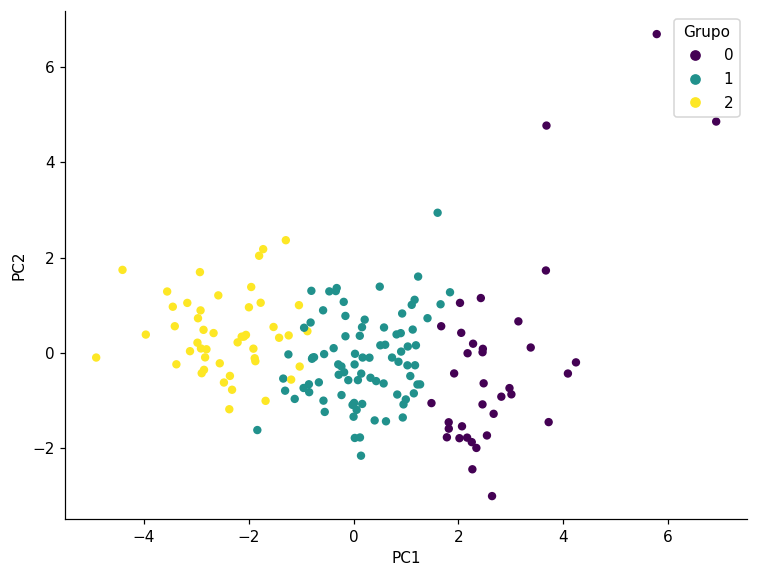

,country,child_mort
66,Haiti,208.0
132,Sierra Leone,160.0
32,Chad,150.0
31,Central African Republic,149.0
97,Mali,137.0
113,Nigeria,130.0
112,Niger,123.0
3,Angola,119.0
25,Burkina Faso,116.0
37,"Congo, Dem. Rep.",116.0


In [19]:
# Tarefas 6.1 e 6.2
perfil = X.assign(grupo=grupos).groupby("grupo").mean().round(1)
perfil["n_paises"] = np.bincount(grupos)
display(perfil)

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=grupos, cmap="viridis", s=20)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(*sc.legend_elements(), title="Grupo")
plt.show()

nomes = {0: "Alta renda e baixo risco", 1: "Renda média, em desenvolvimento", 2: "Alta vulnerabilidade (prioridade)"}

g_prior = perfil["child_mort"].idxmax()
df.loc[grupos == g_prior, ["country", "child_mort"]].sort_values("child_mort", ascending=False).head(10)

**Questão 8.** Descreva cada grupo com base na tabela de perfil e indique quais países a ONG deveria priorizar, justificando com os indicadores.

**Resposta:**

**Grupo 0 (36 países): alta renda e baixo risco.** `child_mort` média de 5,0, `income` de 45.672, `gdpp` de 42.494, `life_expec` de 80,1 anos e `total_fer` de 1,8. São os países mais ricos e com melhores indicadores de saúde, os de menor prioridade.

**Grupo 1 (84 países): renda média, em desenvolvimento.** `child_mort` de 21,9, `income` de 12.306, `gdpp` de 6.487, `life_expec` de 72,8 anos e `total_fer` de 2,3. É o maior grupo e fica no meio em todos os indicadores.

**Grupo 2 (47 países): alta vulnerabilidade.** `child_mort` de 93,0, `income` de 3.942, `gdpp` de 1.922, `life_expec` de 59,2 anos, `total_fer` de 5,0 e `inflation` de 12,0, a maior. É o grupo com a pior situação em quase todos os indicadores.

**Prioridade:** a ONG deveria priorizar os países do grupo 2. Entre eles, os 10 com maior mortalidade infantil são Haiti (208), Sierra Leone (160), Chad (150), Central African Republic (149), Mali (137), Nigeria (130), Niger (123), Angola (119), Burkina Faso (116) e Congo, Dem. Rep. (116), todos bem acima da média do grupo (93,0) e muito acima da média da base (38,3).

**Questão 9.** Discuta os riscos de a ONG basear a distribuição de recursos exclusivamente neste agrupamento. Considere, entre outros aspectos: países próximos da fronteira entre grupos, a atualidade e a procedência dos dados, os indicadores escolhidos e a dificuldade de explicar decisões baseadas em componentes principais.

**Resposta:**

- **Países na fronteira entre grupos:** a silhueta ficou em torno de 0,3, então os grupos não são bem separados. Um país com valores intermediários pode ir para um grupo ou outro por uma pequena diferença, e isso mudaria quanto ele recebe. Os países hipotéticos A e B do exercício mostram isso: valores parecidos, em grupos diferentes.
- **Atualidade e procedência dos dados:** a base não informa o ano de referência dos indicadores nem a fonte original. Se os dados forem antigos, o grupo de um país pode já estar desatualizado, por exemplo após uma crise ou um desastre recente.
- **Indicadores escolhidos:** são só 9 indicadores. Ficam de fora fatores como conflitos, desastres, acesso a água e saneamento, desigualdade dentro do país e capacidade do país de receber a ajuda. Além disso, o dicionário descreve `inflation` como crescimento do PIB, o que é ambíguo. Também há valores extremos, como a inflação de 104% da Nigéria, que podem distorcer os grupos.
- **K-Means força 3 grupos:** todo país tem que entrar em um deles, mesmo os atípicos (como Luxembourg, Singapore ou Qatar).
- **Difícil explicar:** os componentes principais são combinações de vários indicadores, e é complicado justificar para doadores ou auditores por que um país ficou em um grupo com base em "PC1". O agrupamento por indicadores originais é mais fácil de explicar.

Por isso o agrupamento deve ser usado como uma triagem inicial e deve ser combinado com análise de especialistas e dados mais atuais antes da decisão final.

## Parte 7 — Persistência e uso do modelo

**Tarefa 7.1.** Salve, no arquivo `modelo_paises.pkl`, um único objeto contendo o pipeline `modelo`, a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`. Faça o download do arquivo.

**Tarefa 7.2.** Carregue o arquivo em uma nova variável e classifique os dois países hipotéticos abaixo, informando os valores **na escala original**:

| Indicador | País A | País B |
|---|---|---|
| `child_mort` | 60 | 45 |
| `exports` | 25 | 30 |
| `health` | 5,0 | 5,5 |
| `imports` | 35 | 40 |
| `income` | 5.000 | 6.000 |
| `inflation` | 8 | 7 |
| `life_expec` | 65 | 67 |
| `total_fer` | 3,5 | 3,0 |
| `gdpp` | 2.500 | 3.000 |

In [20]:
# Tarefas 7.1 e 7.2
joblib.dump({"modelo": modelo, "colunas": list(X.columns), "nomes": nomes}, "modelo_paises.pkl")

# download só funciona no Colab; no VS Code o arquivo já fica na pasta do notebook
try:
    from google.colab import files
    files.download("modelo_paises.pkl")
except ImportError:
    print("Arquivo salvo na pasta do notebook: modelo_paises.pkl")

carregado = joblib.load("modelo_paises.pkl")
novos = pd.DataFrame(
    [[60, 25, 5.0, 35, 5000, 8, 65, 3.5, 2500],
     [45, 30, 5.5, 40, 6000, 7, 67, 3.0, 3000]],
    columns=carregado["colunas"], index=["País A", "País B"])

pred = carregado["modelo"].predict(novos[carregado["colunas"]])
for pais, g in zip(novos.index, pred):
    print(pais, "→ grupo", g, "·", carregado["nomes"][int(g)])

Arquivo salvo na pasta do notebook: modelo_paises.pkl
País A → grupo 2 · Alta vulnerabilidade (prioridade)
País B → grupo 1 · Renda média, em desenvolvimento


**Questão 10.** Por que foi possível informar os valores na escala original, sem padronizá-los nem aplicar o PCA manualmente? Comente também o resultado obtido para os dois países hipotéticos.

**Resposta:**

Foi possível porque o pipeline guarda dentro dele o `StandardScaler` (com a média e o desvio do treino), o `PCA` e o `KMeans` já ajustados. Ao chamar `predict`, ele aplica as três etapas na ordem certa e com os parâmetros aprendidos no treinamento, então o dado novo precisa estar só na escala original e com as colunas na mesma ordem. Isso evita o erro da aula de padronizar de forma errada ou esquecer uma etapa, que roda sem erro e devolve o grupo errado.

**Resultado:** o País A (`child_mort` 60, `income` 5.000, `gdpp` 2.500, `life_expec` 65) foi para o grupo 2, o de alta vulnerabilidade. O País B (`child_mort` 45, `income` 6.000, `gdpp` 3.000, `life_expec` 67) foi para o grupo 1, o de renda média. Os dois têm valores entre as médias dos grupos 1 e 2 (a mortalidade de 60 e 45 fica entre 21,9 e 93,0), ou seja, são casos de fronteira em que uma pequena diferença nos indicadores muda o grupo, o que reforça o risco discutido na Questão 9.

## Atividades complementares

**A.** Ajuste o pipeline com k = 4 e reconstrua a tabela de perfil. Identifique os países que formam o novo grupo e explique o que os caracteriza.

**B.** Aplique o DBSCAN sobre os dados padronizados e reduzidos pelo PCA do pipeline (`modelo[:-1].transform(X)`). Ajuste `eps` e `min_samples` de modo que no máximo 10 países sejam classificados como ruído, liste-os e explique, a partir dos indicadores originais, por que cada um é atípico.

In [21]:
# Atividade complementar A
modelo4 = make_pipeline(StandardScaler(), PCA(n_components=0.9),
                        KMeans(n_clusters=4, n_init=10, random_state=42))
grupos4 = modelo4.fit_predict(X)
perfil4 = X.assign(grupo=grupos4).groupby("grupo").mean().round(1)
perfil4["n_paises"] = np.bincount(grupos4)
display(perfil4)
# o grupo novo é o menor: veja quais países estão nele
menor = perfil4["n_paises"].idxmin()
print(list(paises[grupos4 == menor]))

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,n_paises
grupo,,,,,,,,,,
0,21.9,41.3,6.3,47.9,12969.3,7.5,72.7,2.3,6885.5,89
1,5.0,45.8,9.2,39.7,45250.0,2.7,80.4,1.8,43333.3,30
2,95.1,28.6,6.3,42.3,3539.8,12.0,59.1,5.1,1766.7,45
3,4.1,176.0,6.8,156.7,64033.3,2.5,81.4,1.4,57566.7,3


['Luxembourg', 'Malta', 'Singapore']


**Resposta (A):**

Com k = 4 surgiu um grupo novo, o grupo 3, com só 3 países: **Luxembourg, Malta e Singapore**. O que os caracteriza é o comércio exterior muito acima dos demais: `exports` média de 176 e `imports` de 156,7 (% do PIB), contra cerca de 40 a 58 e 40 a 51 nos outros grupos. Também têm renda alta (`income` de 64.033, `gdpp` de 57.567), `life_expec` de 81,4 anos, `child_mort` de 4,1 e `total_fer` de 1,4. São pequenas economias que funcionam como centros de comércio e finanças. Os outros grupos ficaram parecidos com os do k = 3 (renda média com 89 países, alta renda com 30 e alta vulnerabilidade com 45), com pequenos ajustes de países na fronteira.

In [22]:
# Atividade complementar B
from sklearn.cluster import DBSCAN
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    for ms in [3, 5]:
        r = DBSCAN(eps=eps, min_samples=ms).fit(Z90).labels_
        print(f"eps={eps} · min_samples={ms} · ruído: {(r == -1).sum()} · grupos: {len(set(r) - {-1})}")

# depois de escolher o par que dá ≤ 10 ruídos:
db = DBSCAN(eps=2.5, min_samples=3).fit(Z90)     # ajuste eps e min_samples aqui
ruido = paises[db.labels_ == -1]
display(df.loc[ruido.index])

eps=1.0 · min_samples=3 · ruído: 47 · grupos: 3
eps=1.0 · min_samples=5 · ruído: 55 · grupos: 2
eps=1.5 · min_samples=3 · ruído: 15 · grupos: 2
eps=1.5 · min_samples=5 · ruído: 20 · grupos: 1
eps=2.0 · min_samples=3 · ruído: 8 · grupos: 1
eps=2.0 · min_samples=5 · ruído: 9 · grupos: 1
eps=2.5 · min_samples=3 · ruído: 5 · grupos: 1
eps=2.5 · min_samples=5 · ruído: 5 · grupos: 1
eps=3.0 · min_samples=3 · ruído: 5 · grupos: 1
eps=3.0 · min_samples=5 · ruído: 5 · grupos: 1


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
113,Nigeria,130.0,25.3,5.07,17.4,5150,104.000,60.5,5.84,2330
123,Qatar,9.0,62.3,1.81,23.8,125000,6.980,79.5,2.07,70300
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


**Resposta (B):**

Com `eps=2.5` e `min_samples=3`, o DBSCAN classificou 5 países como ruído (dentro do limite de 10) e formou um único grupo com o resto. Os países são:

- **Luxembourg:** `exports` de 175 e `imports` de 142 (% do PIB) e `gdpp` de 105.000, valores muito acima da média da base.
- **Malta:** `exports` de 153 e `imports` de 154, comércio exterior muito grande em relação ao PIB.
- **Singapore:** `exports` de 200 e `imports` de 174, os maiores da base, com `life_expec` de 82,7 anos e `total_fer` de 1,15 (o menor).
- **Qatar:** `income` de 125.000 (o maior da base) e `health` de 1,81 (o menor gasto em saúde).
- **Nigeria:** `inflation` de 104 (o maior valor da base), `child_mort` de 130 e `total_fer` de 5,84, uma combinação rara de crise econômica com indicadores de saúde ruins.

Quatro deles são atípicos por causa de comércio ou renda extremamente altos, e a Nigéria é atípica pelo lado oposto, com inflação e mortalidade infantil muito altas.